# 01 데이터 점검과 바닥 점수

1. train 150개를 `X`, `y`, `names`로 읽고 형태·결측·평균·진폭을 확인한다.
2. 베이스라인이 넘어야 할 바닥 점수 두 개: (a) 전부 고장 (b) 데이터 소개 PDF의 RMS 관리도

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import fbeta_score, confusion_matrix

plt.rcParams["font.family"] = "Malgun Gothic"  # 그림 속 한글
plt.rcParams["axes.unicode_minus"] = False     # 한글 글꼴에서 음수 부호 깨짐 방지

ROOT = Path.cwd().parent  # 노트북은 notebooks/ 에서 실행된다
sys.path.insert(0, str(ROOT))
from src.data import load_dataset

X, y, names = load_dataset(ROOT / "data" / "TeamProject_train_변경")

## 1. 형태·결측 확인

In [2]:
print("X shape:", X.shape)
print("정상/고장 수:", (y == 0).sum(), (y == 1).sum())
print("NaN 개수:", np.isnan(X).sum())
print("names 앞뒤:", names[:2], names[-2:])
# 라벨과 파일 이름 접두어가 맞는지 (nor_ → 0, abn_ → 1)
print("라벨·이름 일치:", all((n.startswith("abn")) == bool(l) for n, l in zip(names, y)))

X shape: (150, 50000)
정상/고장 수: 120 30
NaN 개수: 0
names 앞뒤: ['nor_001', 'nor_002'] ['abn_029', 'abn_030']
라벨·이름 일치: True


## 2. 파일별 평균(영점 편향)과 최대 절댓값

In [3]:
summary = pd.DataFrame({
    "name": names,
    "label": y,
    "mean": X.mean(axis=1),
    "std": X.std(axis=1),
    "max_abs": np.abs(X - X.mean(axis=1, keepdims=True)).max(axis=1),
})
print(summary.groupby("label")[["mean", "std", "max_abs"]].describe().T.round(4))

# 평균이 다른 파일보다 크게 어긋난 파일 (중앙값에서 0.5 g 이상)
off = summary[(summary["mean"] - summary["mean"].median()).abs() > 0.5]
print("\n평균이 크게 어긋난 파일:")
print(off.round(4).to_string(index=False))

label                 0        1
mean    count  120.0000  30.0000
        mean    -0.0054  -0.0207
        std      0.1387   0.1938
        min     -0.8677  -1.0449
        25%      0.0102   0.0131
        50%      0.0164   0.0172
        75%      0.0211   0.0218
        max      0.0627   0.0289
std     count  120.0000  30.0000
        mean     0.0357   0.0733
        std      0.0285   0.0999
        min      0.0045   0.0017
        25%      0.0211   0.0313
        50%      0.0293   0.0509
        75%      0.0421   0.0796
        max      0.1693   0.5681
max_abs count  120.0000  30.0000
        mean     0.3554   1.4446
        std      0.4187   1.6958
        min      0.0219   0.0522
        25%      0.1330   0.3643
        50%      0.2219   0.9507
        75%      0.4043   1.4978
        max      2.4574   8.0428

평균이 크게 어긋난 파일:
   name  label    mean    std  max_abs
nor_097      0 -0.8677 0.1669   0.5302
nor_101      0 -0.8674 0.1683   0.6765
nor_120      0 -0.8634 0.1693   0.6165
abn

## 3. 바닥 점수 (a) 전부 고장으로 예측

정밀도 P = 30/150 = 0.2, 재현율 R = 1 → F₂ = 5PR/(4P+R) = 1.0/1.8 ≈ 0.556

In [4]:
pred_all = np.ones_like(y)
print("F2 (전부 고장):", round(fbeta_score(y, pred_all, beta=2), 3))
print("손 계산:", round(5 * 0.2 * 1 / (4 * 0.2 + 1), 3))

F2 (전부 고장): 0.556
손 계산: 0.556


## 4. 바닥 점수 (b) RMS 관리도 (데이터 소개 PDF 방식)

- 파일마다 RMS 하나 → train 정상 120개의 RMS로 CL = 평균, UCL = 평균 + 3σ
- UCL 초과 = 고장. 한계를 정한 정상 파일로 다시 평가하므로 train 안에서의 점수다
- PDF는 원신호 RMS를 썼다. 평균 제거 후 RMS도 함께 본다

In [5]:
def control_chart(stat, y):
    """정상의 평균+3σ를 UCL로 두고 초과하면 고장으로 판정"""
    cl = stat[y == 0].mean()
    ucl = cl + 3 * stat[y == 0].std(ddof=1)
    pred = (stat > ucl).astype(int)
    return cl, ucl, pred

rms_raw = np.sqrt((X ** 2).mean(axis=1))
rms_demean = X.std(axis=1)  # 평균 제거 후 RMS = 표준편차

for label, stat in [("원신호 RMS", rms_raw), ("평균제거 RMS", rms_demean)]:
    cl, ucl, pred = control_chart(stat, y)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    print(f"{label}: CL={cl:.3f}, UCL={ucl:.3f} | TP={tp} FN={fn} FP={fp} TN={tn} | "
          f"F2={fbeta_score(y, pred, beta=2):.3f}")
    print("  UCL 초과 파일:", [n for n, p in zip(names, pred) if p])

원신호 RMS: CL=0.059, UCL=0.460 | TP=2 FN=28 FP=3 TN=117 | F2=0.080
  UCL 초과 파일: ['nor_097', 'nor_101', 'nor_120', 'abn_015', 'abn_016']
평균제거 RMS: CL=0.036, UCL=0.121 | TP=2 FN=28 FP=3 TN=117 | F2=0.080
  UCL 초과 파일: ['nor_097', 'nor_101', 'nor_120', 'abn_015', 'abn_016']


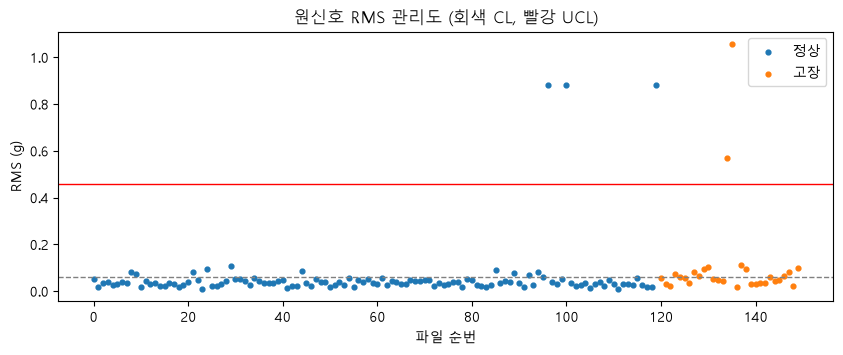

In [6]:
cl, ucl, _ = control_chart(rms_raw, y)
fig, ax = plt.subplots(figsize=(10, 3.5))
idx = np.arange(len(y))
ax.scatter(idx[y == 0], rms_raw[y == 0], s=12, label="정상")
ax.scatter(idx[y == 1], rms_raw[y == 1], s=12, label="고장")
ax.axhline(cl, ls="--", lw=1, color="gray")
ax.axhline(ucl, ls="-", lw=1, color="red")
ax.set_xlabel("파일 순번")
ax.set_ylabel("RMS (g)")
ax.set_title("원신호 RMS 관리도 (회색 CL, 빨강 UCL)")
ax.legend()
plt.show()